# AVAX SHORT — Bollinger + RSI, **nhiều lệnh chồng nhau**, train full grid trên GPU

Notebook này dùng `train_full_grid_gpu.py` cùng thư mục (logic chung ở `reference/multi_position/multi_position_engine.py`). Sửa **ô Cấu hình**, rồi chọn **Run All**. Kết quả lưu thành CSV cạnh notebook.

**Vào lệnh tại nến `i`:** `close[i-1] > lower[i] > close[i]` **và** `RSI(rsi_window)[i] < rsi_threshold`. **Risk:** `sl_multiplier × (upper[i] − entry)`; stop = entry + risk, TP = entry − `tp_sl_ratio` × risk. Timeout `MAX_HOLDING_BARS` nến; phí vào lệnh `0.001 / sl_ratio` (bỏ lệnh nếu > 0.2R); phí giữ lệnh `0.0001 × (số nến / FEE_BARS) / sl_ratio`.

**Khác bản gốc `reference/short_bollinger+RSI`:** bản gốc giữ **một lệnh** và bỏ mọi tín hiệu xuất hiện khi lệnh đang mở. Ở đây **mỗi tín hiệu mở một lệnh riêng**; mỗi lệnh có stop/TP/timeout riêng, đóng độc lập. Tại mỗi nến: (1) xét tín hiệu, (2) xét thoát cho các lệnh đang mở (timeout → stop → TP → hết dữ liệu), (3) thêm lệnh mới (bắt đầu xét thoát từ nến sau). `MAX_OPEN` giới hạn số lệnh mở cùng lúc (tối đa 64); **`MAX_OPEN = 1` cho kết quả trùng tuyệt đối bản gốc** (cùng phí).

**Đọc kết quả:** R tính **cho mỗi lệnh**. Khi N lệnh mở cùng lúc, rủi ro thực là N·R, nên R/tháng của bản nhiều lệnh không so thẳng được với bản 1 lệnh. Các cột thêm: `mtm_max_dd` (drawdown khi định giá cả lệnh đang mở theo close mỗi nến), `max_concurrent` / `avg_concurrent` (số lệnh mở tối đa / trung bình mỗi nến), `skipped_entries` (tín hiệu bị bỏ vì đã đủ `MAX_OPEN`). Ô so sánh đặt cạnh `r_per_month / max_concurrent` — lợi nhuận nếu chia vốn rủi ro cho số lệnh tối đa.

**Phí giữ lệnh:** mỗi 8 giờ (`FEE_BARS = None` ⇒ 32 ở 15min). Giống bản short gốc (32 ở 15min). Grid search trên toàn khoảng train là **in-sample**; đánh giá ngoài mẫu bằng `reference/walk_forward_15min.py --folders multi_position/short_bollinger+RSI`.

In [1]:
# CẤU HÌNH — sửa ô này trước khi chạy
TIMEFRAME = "15min"                 # ví dụ "5min", "15min", "1h", "4h"
START_DATE = "2023-07-01"          # ngày bắt đầu, bao gồm ngày này
END_DATE = "2025-07-01"            # ngày kết thúc, bao gồm ngày này
DATA_CSV = None                     # None = CSV 5min của thư mục short_bollinger+RSI gốc
SCRIPT_PATH = None                  # None = tự tìm train_full_grid_gpu.py

SCORE_FORMULA = "performance/max_dd*r2**5"
# Sửa trực tiếp các danh sách dưới đây để đổi grid. Số bộ tham số là tích số giá trị mỗi danh sách.
SEARCH_SPACES = {
    "boll_window": [6, 8, 10, 12, 14, 16, 18, 20, 25, 30],
    "boll_window_dev": [1.7, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3],
    "rsi_window": [30, 35, 40, 45, 50, 60, 80],
    "rsi_threshold": [35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49],
    "sl_multiplier": [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0],
    "tp_sl_ratio": [1.1],
}
LIMIT = None                         # None = toàn bộ bộ tham số; số nguyên để chạy thử
MAX_HOLDING_BARS = 288             # số nến tối đa giữ lệnh theo TIMEFRAME
MAX_OPEN = 64                       # số lệnh mở cùng lúc tối đa (1 = bản gốc một lệnh; tối đa 64)
FEE_BARS = None                    # None = 8 giờ mỗi lần phí (32 ở 15min)
VERIFY_SAMPLES = 0                  # 0 = bỏ qua so với CPU; ví dụ 8 = kiểm tra 8 bộ
MIN_TRADES = 50                     # bảng xếp hạng chỉ giữ bộ có nhiều lệnh hơn số này
OUTPUT_CSV = None                   # None = CSV theo timeframe, cạnh notebook

In [2]:
# Nạp script cùng thư mục (cũng hoạt động khi kernel bắt đầu ở thư mục khác trong repo)
from pathlib import Path
import importlib.util
import itertools
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SIDE_FOLDER = "short_bollinger+RSI"
if SCRIPT_PATH is None:
    candidates = []
    for parent in (Path.cwd(), *Path.cwd().parents):
        if parent.name == SIDE_FOLDER and parent.parent.name == "multi_position":
            candidates.append(parent / "train_full_grid_gpu.py")
        candidates.append(parent / "multi_position" / SIDE_FOLDER / "train_full_grid_gpu.py")
        candidates.append(parent / "reference" / "multi_position" / SIDE_FOLDER / "train_full_grid_gpu.py")
    script_path = next((path.resolve() for path in candidates if path.is_file()), None)
    if script_path is None:
        raise FileNotFoundError("Không tìm thấy train_full_grid_gpu.py; hãy đặt SCRIPT_PATH ở ô Cấu hình")
else:
    script_path = Path(SCRIPT_PATH).expanduser().resolve()
if not script_path.is_file():
    raise FileNotFoundError(script_path)

spec = importlib.util.spec_from_file_location("avax_multi_short_bollinger_RSI", script_path)
strategy = importlib.util.module_from_spec(spec)
spec.loader.exec_module(strategy)
csv_path = Path(DATA_CSV).expanduser().resolve() if DATA_CSV else strategy.DEFAULT_CSV
if not csv_path.is_file():
    raise FileNotFoundError(csv_path)
if not 1 <= MAX_OPEN <= strategy.MAX_SLOTS:
    raise ValueError(f"MAX_OPEN phải trong khoảng 1..{strategy.MAX_SLOTS}")
print("CSV:", csv_path)
print("Đã nạp:", script_path)
print("Phí giữ lệnh: mỗi", strategy.resolve_fee_bars(TIMEFRAME, FEE_BARS), "nến; MAX_OPEN =", MAX_OPEN)

CSV: C:\Users\Legion\Desktop\TradingProject\reference\short_bollinger+RSI\avaxusdt_futures_5min.csv
Đã nạp: C:\Users\Legion\Desktop\TradingProject\reference\multi_position\short_bollinger+RSI\train_full_grid_gpu.py
Phí giữ lệnh: mỗi 32.0 nến; MAX_OPEN = 64


In [3]:
# Đọc dữ liệu 5 phút, resample và tạo grid
strategy.timeframe_nanos(TIMEFRAME)
start_date, end_date = START_DATE, END_DATE
expected_keys = set(strategy.SEARCH_SPACE)
space = SEARCH_SPACES
if set(space) != expected_keys:
    raise ValueError(f"SEARCH_SPACES cần đúng các khóa: {sorted(expected_keys)}")
for name, values in space.items():
    if not isinstance(values, (list, tuple)) or not values:
        raise ValueError(f"{name} phải là danh sách có ít nhất một giá trị")
space = {name: list(values) for name, values in space.items()}

bars = strategy.load_bars(csv_path, TIMEFRAME, start_date, end_date)
combinations = itertools.product(*(space[name] for name in space))
if LIMIT is not None:
    combinations = itertools.islice(combinations, LIMIT)
grid = pd.DataFrame(combinations, columns=list(space))
print(f"Dữ liệu: {len(bars):,} nến; {bars['timestamp'].iloc[0]} → {bars['timestamp'].iloc[-1]}")
print(f"Grid: {len(grid):,} bộ tham số")
display(grid.head())

Dữ liệu: 69,172 nến; 2023-07-01 00:00:00 → 2025-06-20 12:45:00
Grid: 102,900 bộ tham số


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio
0,6,1.7,30,35,0.7,1.1
1,6,1.7,30,35,0.8,1.1
2,6,1.7,30,35,0.9,1.1
3,6,1.7,30,35,1.0,1.1
4,6,1.7,30,35,1.1,1.1


In [4]:
# Chạy toàn bộ grid trên GPU
result, timing = strategy.run_gpu_grid(
    bars, grid, TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS,
    fee_bars=FEE_BARS,
    score_formula=SCORE_FORMULA,
    max_open=MAX_OPEN,
)
print("Thời gian:", timing)
print(f"Đã tính {len(result):,} bộ tham số")
print(f"Lệnh mở cùng lúc: tối đa {result['max_concurrent'].max()}, trung vị của max {result['max_concurrent'].median():g}; "
      f"tín hiệu bị bỏ vì đủ MAX_OPEN: {int(result['skipped_entries'].sum()):,}")

C:\Users\Legion\anaconda3\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Thời gian: {'indicators_and_transfer_s': 2.2754585999646224, 'holding_fee_bars': 32.0, 'total_gpu_s': 9.909577299957164}
Đã tính 102,900 bộ tham số
Lệnh mở cùng lúc: tối đa 33, trung vị của max 9; tín hiệu bị bỏ vì đủ MAX_OPEN: 0


In [5]:
# TÍNH LẠI SCORE — chạy lại riêng ô này sau khi đổi SCORE_FORMULA
result = strategy.score_result(result, SCORE_FORMULA)
print("Score:", SCORE_FORMULA)

Score: performance/max_dd*r2**5


In [6]:
# Kiểm tra CPU (tùy chọn): đối chiếu mẫu với replay float64
# Có thể lệch rất ít bộ khi giá chạm dải/stop sát ngưỡng làm tròn fp32 (đã gặp ở bản short gốc).
if VERIFY_SAMPLES:
    strategy.verify_samples(bars, result, VERIFY_SAMPLES, MAX_HOLDING_BARS, FEE_BARS, TIMEFRAME, MAX_OPEN)

In [7]:
# Lưu kết quả và xem các bộ tham số đứng đầu
output_path = (Path(OUTPUT_CSV).expanduser().resolve() if OUTPUT_CSV
               else script_path.with_name(f"full_gpu_grid_results_{TIMEFRAME}_fp32.csv"))
output_path.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(output_path, index=False)

ranked = result.loc[(result["number_of_trade"] > MIN_TRADES) & result["score"].notna()].sort_values("score", ascending=False)

print("Đã lưu:", output_path)
print(f"Bộ có score hợp lệ và > {MIN_TRADES} lệnh: {len(ranked):,}/{len(result):,}")
display(ranked.head(20))

Đã lưu: C:\Users\Legion\Desktop\TradingProject\reference\multi_position\short_bollinger+RSI\full_gpu_grid_results_15min_fp32.csv
Bộ có score hợp lệ và > 50 lệnh: 97,963/102,900


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,performance,max_dd,avg_dd,r2,...,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,avg_concurrent,number_of_trade,max_concurrent,skipped_entries,score,score_formula
39350,12,2.2,60,40,1.7,1.1,57.275429,6.210000,1.78,0.941816,...,2.806461,0.862098,0.532895,8.533688,0.620381,271,7,0,6.834489,performance/max_dd*r2**5
28367,10,2.2,40,36,1.0,1.1,36.530903,4.370000,0.95,0.946611,...,1.713109,0.900788,0.593549,4.840388,0.200732,142,4,0,6.353846,performance/max_dd*r2**5
39126,12,2.2,50,39,1.7,1.1,56.023911,6.740000,1.90,0.944300,...,2.843265,0.832345,0.519575,9.386959,0.663231,284,7,0,6.241143,performance/max_dd*r2**5
25414,10,2.0,40,35,1.1,1.1,41.349808,4.640000,1.33,0.930398,...,1.656079,1.054726,0.525691,5.811676,0.262650,168,5,0,6.212979,performance/max_dd*r2**5
38902,12,2.2,45,38,1.7,1.1,57.064087,6.740000,1.66,0.939361,...,2.597936,0.927858,0.552436,9.386959,0.633233,268,7,0,6.192480,performance/max_dd*r2**5
25413,10,2.0,40,35,1.0,1.1,40.920975,4.470000,1.25,0.921007,...,1.807468,0.956362,0.529530,6.476122,0.231177,168,5,0,6.066712,performance/max_dd*r2**5
92611,30,1.7,30,35,0.8,1.1,57.457302,7.230000,2.41,0.946276,...,3.144101,0.771962,0.423320,10.058342,0.413983,317,8,0,6.029709,performance/max_dd*r2**5
14361,8,1.9,60,40,1.8,1.1,66.149384,7.870000,2.66,0.935323,...,3.269874,0.854559,0.490972,10.851139,0.587073,344,8,0,6.016701,performance/max_dd*r2**5
77317,20,2.0,50,37,1.6,1.1,70.170609,7.910000,1.85,0.925279,...,2.934726,1.010032,0.543570,11.503666,0.705632,273,9,0,6.016494,performance/max_dd*r2**5
77318,20,2.0,50,37,1.7,1.1,67.139244,7.860000,1.87,0.921156,...,2.952922,0.960443,0.513843,11.240410,0.730498,273,9,0,5.665257,performance/max_dd*r2**5


In [8]:
# So với bản MỘT lệnh (MAX_OPEN = 1 = bản gốc) trên cùng grid, cùng dữ liệu, cùng phí
one, _ = strategy.run_gpu_grid(bars, grid, TIMEFRAME, max_holding_bars=MAX_HOLDING_BARS,
                               fee_bars=FEE_BARS, score_formula=SCORE_FORMULA, max_open=1)


def summary(frame):
    ok = frame["number_of_trade"] > MIN_TRADES
    f = frame[ok]
    return pd.Series({
        "số bộ > MIN_TRADES": int(ok.sum()),
        "số lệnh (trung vị)": f["number_of_trade"].median(),
        "R/tháng (trung vị)": f["r_per_month"].median(),
        "% bộ có lãi": (f["performance"] > 0).mean(),
        "max DD đã chốt (trung vị, R)": f["max_dd"].median(),
        "max DD MTM (trung vị, R)": f["mtm_max_dd"].median(),
        "Martin (trung vị)": f["r_martin_monthly"].median(),
        "lệnh mở tối đa (trung vị)": f["max_concurrent"].median(),
        "lệnh mở trung bình (trung vị)": f["avg_concurrent"].median(),
        "R/tháng ÷ lệnh mở tối đa (trung vị)": (f["r_per_month"] / f["max_concurrent"].clip(lower=1)).median(),
        "R/tháng ÷ max DD MTM (trung vị)": (f["r_per_month"] / f["mtm_max_dd"]).median(),
    })


comparison = pd.DataFrame({"1 lệnh (gốc)": summary(one), f"nhiều lệnh (MAX_OPEN={MAX_OPEN})": summary(result)})
display(comparison.round(3))
both = (one["number_of_trade"] > MIN_TRADES) & (result["number_of_trade"] > MIN_TRADES)
print(f"Cùng bộ tham số: nhiều lệnh có R/tháng cao hơn ở {(result.loc[both, 'r_per_month'] > one.loc[both, 'r_per_month']).mean():.1%} bộ; "
      f"Martin cao hơn ở {(result.loc[both, 'r_martin_monthly'] > one.loc[both, 'r_martin_monthly']).mean():.1%} bộ")
print(f"Tương quan hạng score giữa hai bản: {result.loc[both, 'score'].corr(one.loc[both, 'score'], method='spearman'):.3f}")

,1 lệnh (gốc),nhiều lệnh (MAX_OPEN=64)
số bộ > MIN_TRADES,93514.000,97963.000
số lệnh (trung vị),269.000,934.000
R/tháng (trung vị),0.474,1.800
% bộ có lãi,0.870,0.926
"max DD đã chốt (trung vị, R)",14.640,36.150
"max DD MTM (trung vị, R)",15.236,38.278
Martin (trung vị),0.083,0.139
lệnh mở tối đa (trung vị),1.000,10.000
lệnh mở trung bình (trung vị),0.378,1.138
R/tháng ÷ lệnh mở tối đa (trung vị),0.474,0.195


Cùng bộ tham số: nhiều lệnh có R/tháng cao hơn ở 88.3% bộ; Martin cao hơn ở 65.6% bộ


Tương quan hạng score giữa hai bản: 0.518


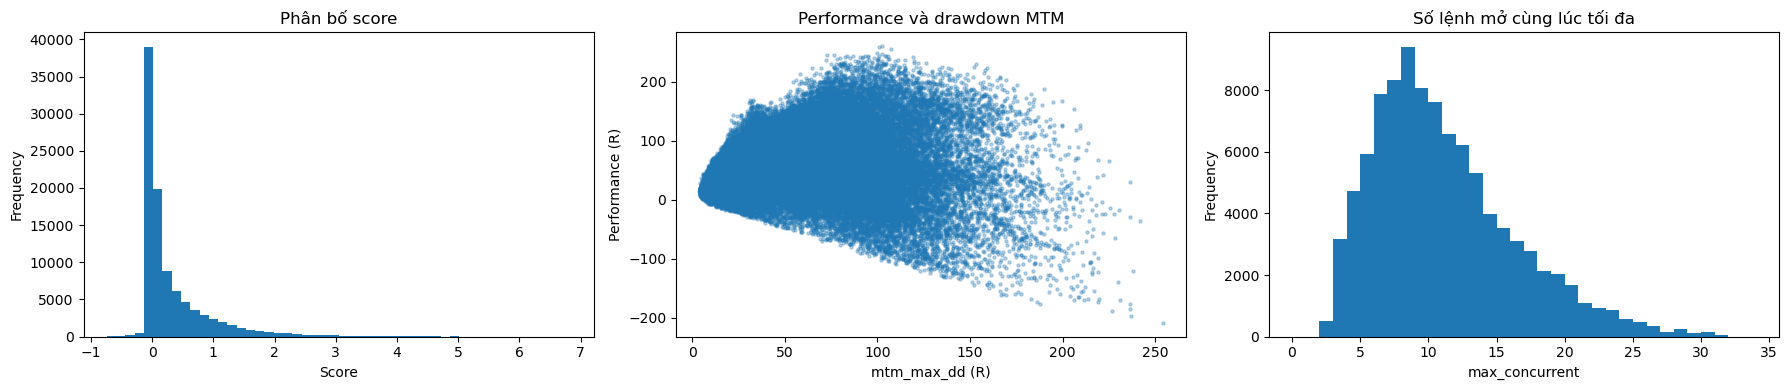

In [9]:
# Biểu đồ: phân bố score, hiệu quả theo drawdown MTM, và số lệnh mở cùng lúc
if ranked.empty:
    print("Không có score hợp lệ để vẽ")
else:
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    ranked["score"].plot.hist(ax=axes[0], bins=50, title="Phân bố score")
    axes[0].set_xlabel("Score")
    axes[1].scatter(ranked["mtm_max_dd"], ranked["performance"], s=5, alpha=0.3)
    axes[1].set(xlabel="mtm_max_dd (R)", ylabel="Performance (R)", title="Performance và drawdown MTM")
    ranked["max_concurrent"].plot.hist(ax=axes[2], bins=range(0, int(ranked["max_concurrent"].max()) + 2),
                                       title="Số lệnh mở cùng lúc tối đa")
    axes[2].set_xlabel("max_concurrent")
    plt.tight_layout()
    plt.show()

C:\Users\Legion\anaconda3\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Giai đoạn backtest: 2023-07-01 00:00:00 đến 2025-06-20 12:45:00


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,performance,max_dd,avg_dd,r2,...,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,avg_concurrent,number_of_trade,max_concurrent,skipped_entries,score,score_formula
backtest_trial,12,2.2,60,40,1.7,1.1,57.275429,6.21,1.78,0.941816,...,2.806461,0.862098,0.532895,8.533688,0.620381,271,7,0,6.834489,performance/max_dd*r2**5


,performance,max_dd,avg_dd,r2,number_of_trade,r_per_month,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,max_concurrent,avg_concurrent,skipped_entries
nhiều lệnh (MAX_OPEN=64),57.275421,6.21,1.78,0.941816,271.0,2.419444,2.806462,0.862098,0.532895,8.533691,7.0,0.620381,0.0
1 lệnh (gốc),18.466187,4.47,0.89,0.945740,98.0,0.780054,1.243083,0.627515,0.451694,5.519694,1.0,0.250101,173.0


,số lệnh
outcome,
take_profit,111
timeout,96
stop,63
end_of_data,1


,entry_index,entry_timestamp,exit_index,close_timestamp,entry_price,risk,stop_loss,take_profit,holding_bars,open_at_entry,outcome,gross_r,entry_fee,holding_fee,net_r
0,426,2023-07-05 10:30:00,692,2023-07-08 05:00:00,12.679,0.854759,13.533759,11.738765,266,1,stop,-1.000000,0.014833,0.012330,-1.027164
1,537,2023-07-06 14:15:00,693,2023-07-08 05:15:00,12.297,1.266578,13.563578,10.903764,156,2,stop,-1.000000,0.009709,0.004733,-1.014442
2,864,2023-07-10 00:00:00,1152,2023-07-13 00:00:00,13.366,0.694904,14.060904,12.601606,288,1,timeout,0.509423,0.019234,0.017311,0.472878
3,865,2023-07-10 00:15:00,1153,2023-07-13 00:15:00,13.343,0.774272,14.117272,12.491301,288,2,timeout,0.481743,0.017233,0.015510,0.449000
4,2268,2023-07-24 15:00:00,2360,2023-07-25 14:00:00,12.950,0.360098,13.310098,12.553892,92,3,stop,-1.000000,0.035962,0.010339,-1.046302
5,2109,2023-07-22 23:15:00,2397,2023-07-25 23:15:00,13.391,0.762568,14.153568,12.552175,288,1,timeout,0.082616,0.017560,0.015804,0.049251
6,2247,2023-07-24 09:45:00,2535,2023-07-27 09:45:00,12.888,1.427545,14.315545,11.317701,288,2,timeout,-0.360759,0.009028,0.008125,-0.377913
7,2959,2023-07-31 19:45:00,2984,2023-08-01 02:00:00,12.786,0.387248,13.173248,12.360028,25,2,take_profit,1.100000,0.033018,0.002580,1.064403
8,2864,2023-07-30 20:00:00,3152,2023-08-02 20:00:00,12.991,0.935479,13.926479,11.961973,288,1,timeout,0.491726,0.013887,0.012498,0.465341
9,2960,2023-07-31 20:00:00,3248,2023-08-03 20:00:00,12.736,0.523605,13.259605,12.160035,288,3,timeout,0.360959,0.024324,0.021891,0.314744


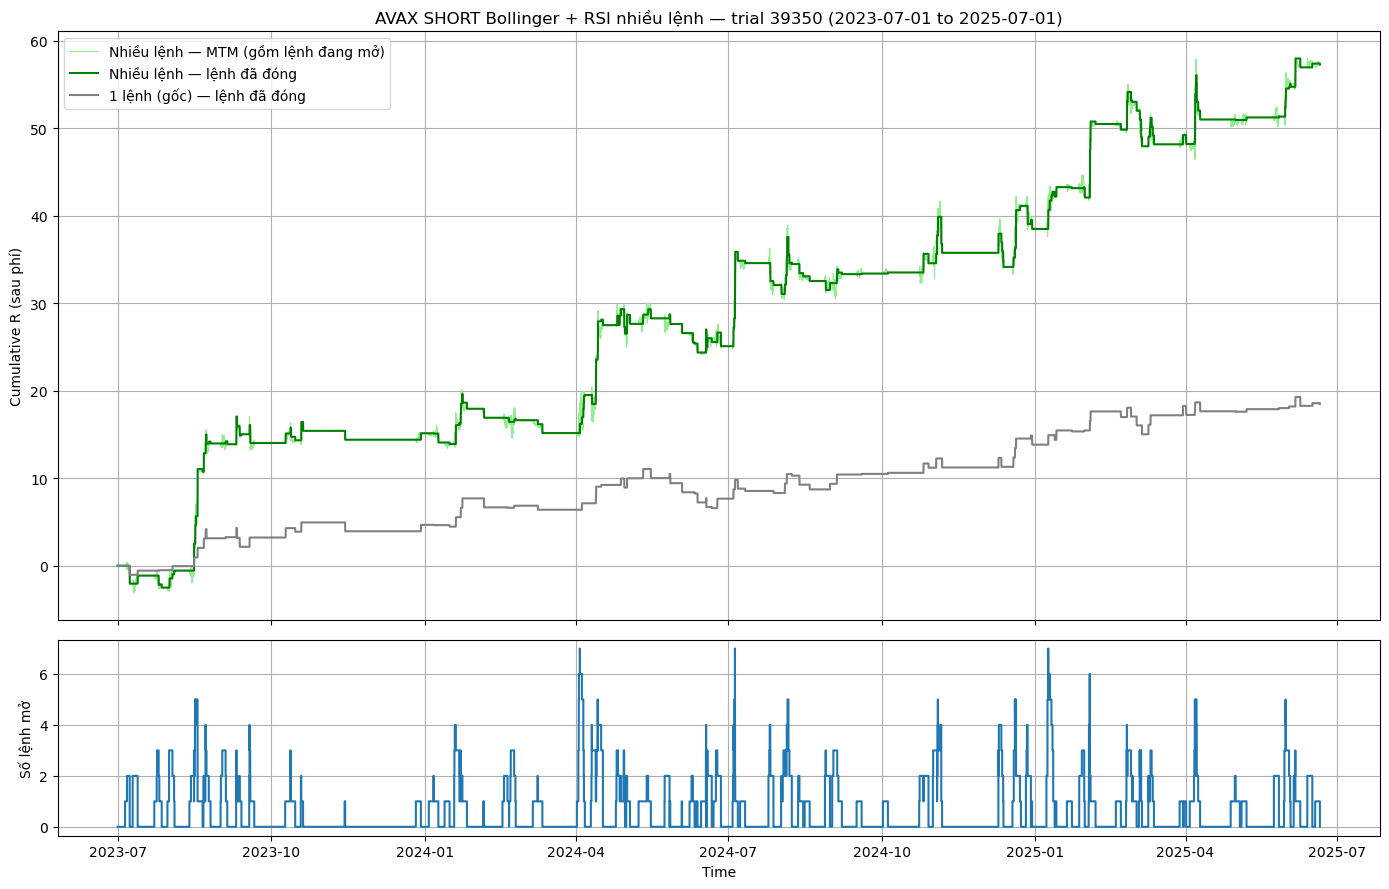

In [10]:
# Điền ID của trial trong bảng `result` (đếm từ 0), rồi chạy riêng ô này. None = bộ đứng đầu `ranked`.
TRIAL_ID = None
BACKTEST_START_DATE = None  # Ví dụ "2024-07-01"; None = ngày bắt đầu train
BACKTEST_END_DATE = None    # Ví dụ "2025-06-20"; None = ngày kết thúc train

import numpy as np

if TRIAL_ID is None:
    if ranked.empty:
        raise ValueError("Bảng ranked rỗng; hãy điền TRIAL_ID")
    TRIAL_ID = int(ranked.index[0])
if TRIAL_ID not in result.index:
    raise KeyError(f"TRIAL_ID={TRIAL_ID} không có trong result.index")
params = grid.loc[TRIAL_ID].to_dict()
backtest_start = BACKTEST_START_DATE or start_date
backtest_end = BACKTEST_END_DATE or end_date
backtest_bars = (bars if BACKTEST_START_DATE is None and BACKTEST_END_DATE is None
                 else strategy.load_bars(csv_path, TIMEFRAME, backtest_start, backtest_end))

# GPU cho đúng một bộ tham số, và replay float64 liệt kê từng lệnh; hai bên phải khớp.
backtest_result, _ = strategy.run_gpu_grid(
    backtest_bars, grid.loc[[TRIAL_ID]].reset_index(drop=True), TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS, fee_bars=FEE_BARS, score_formula=SCORE_FORMULA, max_open=MAX_OPEN)
backtest_trial = backtest_result.iloc[0]
trades = strategy.cpu_trace(backtest_bars, params, TIMEFRAME, MAX_HOLDING_BARS, FEE_BARS, MAX_OPEN)
replay = strategy.trade_metrics(backtest_bars, trades, TIMEFRAME, FEE_BARS)
if replay["number_of_trade"] != int(backtest_trial["number_of_trade"]):
    print(f"Lưu ý: GPU {int(backtest_trial['number_of_trade'])} lệnh, replay float64 {replay['number_of_trade']} "
          "(giá sát ngưỡng làm tròn fp32)")
single = strategy.cpu_trace(backtest_bars, params, TIMEFRAME, MAX_HOLDING_BARS, FEE_BARS, 1)
single_metrics = strategy.trade_metrics(backtest_bars, single, TIMEFRAME, FEE_BARS)

print(f"Giai đoạn backtest: {backtest_bars['timestamp'].iloc[0]} đến {backtest_bars['timestamp'].iloc[-1]}")
display(backtest_trial.to_frame(name="backtest_trial").T)
display(pd.DataFrame({f"nhiều lệnh (MAX_OPEN={MAX_OPEN})": replay, "1 lệnh (gốc)": single_metrics}).T)
display(trades["outcome"].value_counts().to_frame("số lệnh"))
display(trades.head(20))

if trades.empty:
    print("Không có lệnh nào trong khoảng backtest")
else:
    equity = strategy.mtm_equity(backtest_bars, trades, TIMEFRAME, FEE_BARS)
    single_equity = strategy.mtm_equity(backtest_bars, single, TIMEFRAME, FEE_BARS)
    fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    axes[0].plot(equity["timestamp"], equity["mtm_equity"], color="lightgreen", linewidth=0.8,
                 label="Nhiều lệnh — MTM (gồm lệnh đang mở)")
    axes[0].plot(equity["timestamp"], equity["closed_equity"], color="green", label="Nhiều lệnh — lệnh đã đóng")
    axes[0].plot(single_equity["timestamp"], single_equity["closed_equity"], color="gray",
                 label="1 lệnh (gốc) — lệnh đã đóng")
    axes[0].set(ylabel="Cumulative R (sau phí)",
                title=f"AVAX SHORT Bollinger + RSI nhiều lệnh — trial {TRIAL_ID} ({backtest_start} to {backtest_end})")
    axes[0].legend()
    axes[0].grid(True)
    axes[1].step(equity["timestamp"], equity["open_trades"], where="post", color="tab:blue")
    axes[1].set(xlabel="Time", ylabel="Số lệnh mở")
    axes[1].grid(True)
    fig.tight_layout()
    plt.show()

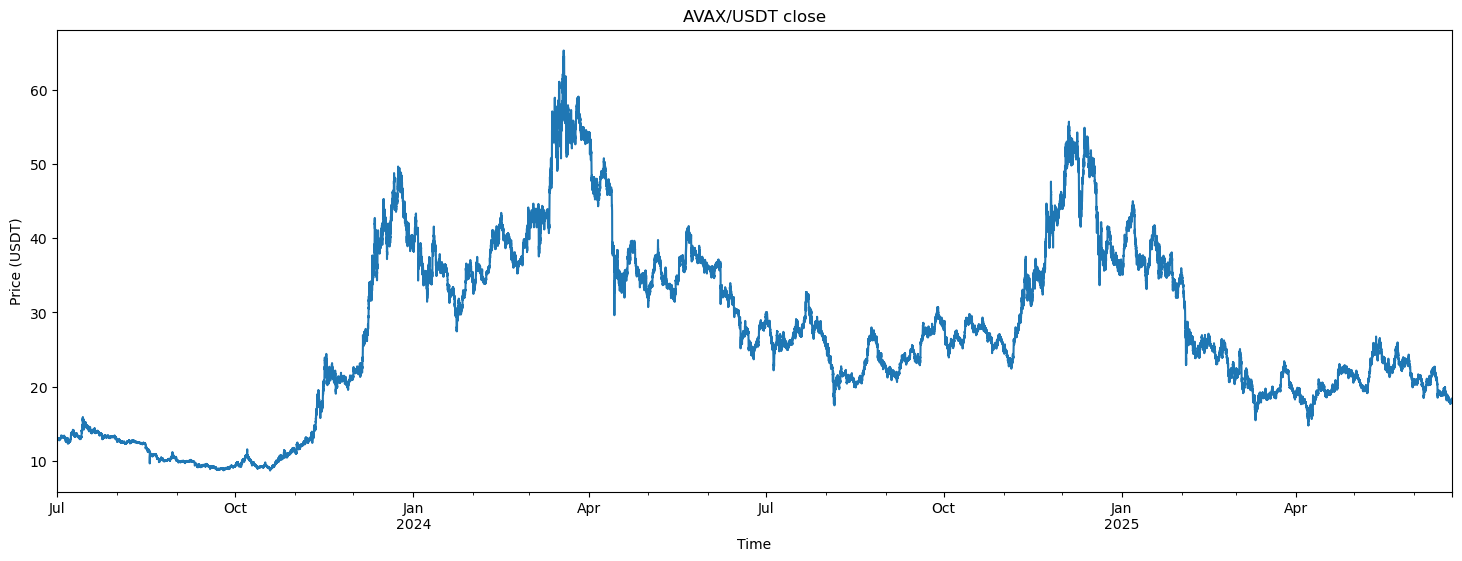

In [11]:
ax = backtest_bars.set_index("timestamp")["close"].plot(figsize=(18, 6))
ax.set(title="AVAX/USDT close", xlabel="Time", ylabel="Price (USDT)")
plt.show()